In [34]:
import pandas as pd
import pyfixest as pf
import numpy as np
import os
import pickle

import cloudpickle
import joblib

def save_model(obj, path):
    """Try cloudpickle/joblib/pickle in order."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if cloudpickle is not None:
        try:
            with open(path, "wb") as f:
                cloudpickle.dump(obj, f)
            return
        except Exception:
            pass
    if joblib is not None:
        try:
            joblib.dump(obj, path, compress=3)
            return
        except Exception:
            pass
    with open(path, "wb") as f:
        pickle.dump(obj, f)

def load_model(path):
    """Load serialized object; try cloudpickle first then joblib then pickle."""
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    if cloudpickle is not None:
        try:
            with open(path, "rb") as f:
                return cloudpickle.load(f)
        except Exception:
            pass
    if joblib is not None:
        try:
            return joblib.load(path)
        except Exception:
            pass
    with open(path, "rb") as f:
        return pickle.load(f)


# --- Control flags ---
# new_models    = True  : re-run all regressions and overwrite cache.
# new_models    = False : load from cache (see load_all_mods below).
# load_all_mods = True  : load full model objects from .cpkl (warning: ~45 GB for cross-sectional).
# load_all_mods = False : load lightweight CSV/tex outputs saved by server run (default).
new_models    = False
load_all_mods = True

cache_prefix = '../data/lightcast_vacancies/reg_output/'
os.makedirs(cache_prefix, exist_ok=True)

if new_models:
    df = pd.read_csv("../data/lightcast_vacancies/lightcast_master.csv")

# Supply Side Wage Adjustment Mechanism Exploration

As a reminder, we have access to 24 million job postings between 2010-2024. We are interested in extracting a single parameter on which to ground a wage adjustment rate to vacancy duration. Below, I outline the regression results of a preliminary attempt. 

I double-checked the full dataset to see whether we can actually extract a panel of vacancies themselves, but I am now fairly certain that this is not possible unless we try to link vacancies with different IDs that we suspect migth be identical. Additionally, Lightcast de-duplicates the job openings themselves. Though I am not sure whether this applies month-by-month, I think it partly explains why we cannot link individual vacancy IDs over time. 

Therefore, after some discussion with Stefi, I have tried the following three options with variations in the estimation strategy listed below each number:

1. Estimate a *cross-sectional* regression on a dataset where observations are individual vacancies. 
    - Include/exclude year-month fixed effects.
    - Down-weight longer vacancy durations due to potential selection effects.
2. Estimate a *panel* regression in which we link *firm-level* occupational wage offers over time, regressing them on *firm-level* occupational vacancy durations.
    - Vary SOC-2, SOC-3, SOC-4, SOC-5 occupational categories.
    - First-differences vs. levels.
3. Estimate a *panel* regression in which we link *industry-level* occupational wage offers over time, regressing them on *industry-level* occupational vacancy durations. 
    - Vary SOC-2, SOC-3, SOC-4, SOC-5 occupational categories.
    - Vary NAICS-2, 3, 4, 5 industrial categories.
    - First-differences vs. levels.

In [22]:
if new_models:
    #df = df[df["year"] <= 2018].copy()
    df["log_wage"] = np.log(df["salary"])
    df["ym"] = df["year"].astype(str) + "-" + df["month"].astype(str).str.zfill(2)

    # Duration in days, weeks, months
    df["duration_days"]   = df["duration"]
    df["duration_weeks"]  = df["duration"] / 7
    df["duration_months"] = df["duration"] / 30.4

    # Inverse duration weights (length-bias correction, based on days)
    df["idw"] = 1 / df["duration_days"]

    print(f"Rows before cleaning: {len(df):,}")

    # Drop invalid rows
    df = df[
        df["log_wage"].notna() &
        df["duration"].notna() &
        df["company"].notna() &
        (df["duration"] > 0) &
        np.isfinite(df["log_wage"])
    ].copy()

    for col in ["company", "soc_3", "naics2", "msa", "ym"]:
        df[col] = df[col].astype("category")
        
    print(f"Rows after cleaning: {len(df):,}")


## Econometric Specifications

### 1. Individual Vacancy-Level Regression

As a baseline, we estimate the following log-linear regression at the 
individual vacancy level:


$\ln w_{i,j,s,l,t} = \beta \cdot \text{dur}_{i,j,s,l,t} + \alpha_j + \alpha_s + \alpha_l + \alpha_t + \varepsilon_{i,j,s,l,t}$

where $\ln w_{i,j,s,l,t}$ is the log of the posted salary for vacancy 
$i$ posted by firm $j$ in occupation $s$, location $l$ (MSA), at 
year-month $t$. $\text{dur}_{i,j,s,l,t}$ is vacancy duration, measured either in days, weeks, and months. The coefficient of interest 
$\beta$ captures the conditional association between duration and posted 
wages within firms, occupations, locations, and time periods. $\alpha_j$, 
$\alpha_s$, $\alpha_l$, and $\alpha_t$ denote firm, occupation, location, 
and year-month fixed effects respectively. Standard errors are clustered 
at the firm level. We also attempt excluding the time fixed effect as the wage response is likely aggregate.

To address length-biased sampling, whereby longer-duration vacancies are 
mechanically over-represented in any cross-sectional scrape of job 
postings, we re-estimate this specification with 
inverse-duration weights $\omega_i = 1/\text{dur}_i$, which downweight 
long-duration observations proportionally.


In [58]:
# ===========================================================================
# PART 1: Individual vacancy-level regressions
# ===========================================================================
# new_models=True  : fit models on raw data and save to cache.
# load_all_mods=True : load full model objects from .cpkl (warning: ~45 GB).
# default (both False): load lightweight CSV/tex outputs from server run.

cs_cache = f'{cache_prefix}vacancy_cross_section_results.cpkl'
all_mods = None

if new_models:
    fit_weeks = pf.feols(
        "log_wage ~ duration_weeks | company + soc_3 + naics2 + msa + ym",
        data=df, vcov={"CRV1": "company"})

    fit_weeks_idw = pf.feols(
        "log_wage ~ duration_weeks | company + soc_3 + naics2 + msa + ym",
        data=df, weights="idw", vcov={"CRV1": "company"})

    fit_weeks_no_ym = pf.feols(
        "log_wage ~ duration_weeks | company + soc_3 + naics2 + msa",
        data=df, vcov={"CRV1": "company"})

    fit_weeks_idw_no_ym = pf.feols(
        "log_wage ~ duration_weeks | company + soc_3 + naics2 + msa",
        data=df, weights="idw", vcov={"CRV1": "company"})

    fit_months = pf.feols(
        "log_wage ~ duration_months | company + soc_3 + naics2 + msa + ym",
        data=df, vcov={"CRV1": "company"})

    fit_months_idw = pf.feols(
        "log_wage ~ duration_months | company + soc_3 + naics2 + msa + ym",
        data=df, weights="idw", vcov={"CRV1": "company"})

    fit_months_no_ym = pf.feols(
        "log_wage ~ duration_months | company + soc_3 + naics2 + msa",
        data=df, vcov={"CRV1": "company"})

    fit_months_idw_no_ym = pf.feols(
        "log_wage ~ duration_months | company + soc_3 + naics2 + msa",
        data=df, weights="idw", vcov={"CRV1": "company"})

    all_mods = [
        fit_weeks, fit_weeks_idw, fit_weeks_no_ym, fit_weeks_idw_no_ym,
        fit_months, fit_months_idw, fit_months_no_ym, fit_months_idw_no_ym,
    ]
    save_model(all_mods, cs_cache)
    print(f"Saved: {cs_cache}")

elif load_all_mods:
    # Load full model objects — requires ~45 GB RAM and matching package versions
    all_mods = load_model(cs_cache)
    print(f"Loaded model objects: {cs_cache}")

else:
    # Lightweight: read saved CSV/tex outputs from server run
    print("Loading cross-sectional results from saved CSV/tex (all_mods not loaded).")
    tidy_df = pd.read_csv(f'{cache_prefix}coefs_cross_section_tidy.csv')
    display(tidy_df)
    print(f"\nTeX table: {cache_prefix}table_cross_section.tex")

Loading cross-sectional results from saved CSV/tex (all_mods not loaded).


,Coefficient,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,model
0,duration_weeks,-0.000427,0.000951,-0.449229,0.653266,-0.002292,0.001437,Weeks
1,duration_weeks,0.000820,0.001092,0.750986,0.452662,-0.001320,0.002960,Weeks (IDW)
2,duration_weeks,0.003361,0.000812,4.137956,0.000035,0.001769,0.004953,Weeks no-YM
3,duration_weeks,0.014435,0.001523,9.479445,0.000000,0.011450,0.017419,Weeks IDW no-YM
4,duration_months,-0.001856,0.004131,-0.449229,0.653266,-0.009953,0.006241,Months
5,duration_months,0.003561,0.004742,0.750986,0.452662,-0.005732,0.012854,Months (IDW)
6,duration_months,0.014598,0.003528,4.137956,0.000035,0.007684,0.021512,Months no-YM
7,duration_months,0.062687,0.006613,9.479445,0.000000,0.049726,0.075648,Months IDW no-YM



TeX table: ../data/lightcast_vacancies/reg_output/table_cross_section.tex


In [61]:
# Only runs when all_mods is available (new_models=True or load_all_mods=True)
all_mods = load_model(cs_cache)
print(f"Loaded model objects: {cs_cache}")
if all_mods is not None:
    
    html = pf.etable(all_mods, type="tex",
        labels={"duration_weeks": "Duration (weeks)", "duration_months": "Duration (months)"},
        model_heads=["Weeks", "Weeks (IDW)", "Weeks", "Weeks (IDW)",
                     "Months", "Months (IDW)", "Months", "Months (IDW)"])
    with open(f'{cache_prefix}table_cross_section.tex', 'w') as f:
        f.write(html)

    rows = []
    names = ["Weeks", "Weeks (IDW)", "Weeks no-YM", "Weeks IDW no-YM",
             "Months", "Months (IDW)", "Months no-YM", "Months IDW no-YM"]
    for name, m in zip(names, all_mods):
        tidy = m.tidy()
        tidy["model"] = name
        rows.append(tidy)
    pd.concat(rows).to_csv(f'{cache_prefix}coefs_cross_section_tidy.csv', index=True)

    print("\n=== Individual Vacancy-Level Results ===")
    display(pf.etable(
        all_mods,
        labels={
            "log_wage":        "(log) Wage",
            "duration_weeks":  "Duration (weeks)",
            "duration_months": "Duration (months)",
            "ym":              "Time (Year-Month)",
            "company":         "Firm",
            "msa":             "Location (MSA)",
            "soc_3":           "Occ. (SOC3)",
            "naics2":          "Ind. (NAICS2)"
        },
        model_heads=["Weeks", "Weeks (IDW)", "Weeks", "Weeks (IDW)",
                     "Months", "Months (IDW)", "Months", "Months (IDW)"]
    ), type = "tex")
else:
    print("all_mods not loaded — set load_all_mods=True to use etable interactively.")

Loaded model objects: ../data/lightcast_vacancies/reg_output/vacancy_cross_section_results.cpkl

=== Individual Vacancy-Level Results ===


GT(_tbl_data=   level_0               level_1                    0                   1  \
0     coef      Duration (weeks)  -0.000 <br> (0.001)  0.001 <br> (0.001)   
1     coef     Duration (months)                                            
2       fe           Occ. (SOC3)                    x                   x   
3       fe        Location (MSA)                    x                   x   
4       fe         Ind. (NAICS2)                    x                   x   
5       fe                  Firm                    x                   x   
6       fe     Time (Year-Month)                    x                   x   
7    stats          Observations             18987319            18987319   
8    stats             S.E. type          by: company         by: company   
9    stats         R<sup>2</sup>                0.678               0.686   
10   stats  R<sup>2</sup> Within                0.000               0.000   

                        2                      3                    4  \
0   0.003*** <br> (0.001)  0.014*** <br> (0.002)                        
1                                                 -0.002 <br> (0.004)   
2                       x                      x                    x   
3                       x                      x                    x   
4                       x                      x                    x   
5                       x                      x                    x   
6                       -                      -                    x   
7                18987319               18987319             18987319   
8             by: company            by: company          by: company   
9                   0.656                  0.665                0.678   
10                  0.000                  0.006                0.000   

                     5                      6                      7  
0                                                                     
1   0.004 <br> (0.005)  0.015*** <br> (0.004)  0.063*** <br> (0.007)  
2                    x                      x                      x  
3                    x                      x                      x  
4                    x                      x                      x  
5                    x                      x                      x  
6                    x                      -                      -  
7             18987319               18987319               18987319  
8          by: company            by: company            by: company  
9                0.686                  0.656                  0.665  
10               0.000                  0.000                  0.006  , _body=<great_tables._gt_data.Body object at 0x126c96750>, _boxhead=Boxhead([ColInfo(var='level_0', type=<ColInfoTypeEnum.row_group: 3>, column_label='level_0', column_align='center', column_width=None), ColInfo(var='level_1', type=<ColInfoTypeEnum.stub: 2>, column_label='level_1', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label='(3)', column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label='(4)', column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label='(5)', column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label='(6)', column_align='center', column_width=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label='(7)', column_align='center', column_width=None), ColInfo(var='7', type=<ColInfoTypeEnum.default: 1>, column_label='(8)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x125911a90>, _spanners=Spanners([Spanner

In [ ]:
# with open(f'{cache_prefix}model_summary_table.tex', 'r') as f:
#     tex = f.read()

# tex = tex.replace('SOC_', r'SOC\_')
# tex = tex.replace('NAICS_', r'NAICS\_')
# tex = tex.replace(' — ', ' -- ')

# with open(f'{cache_prefix}model_summary_table.tex', 'w') as f:
#     f.write(tex)

In [45]:
import gc
del all_mods
gc.collect()


4356

In [50]:
# ===========================================================================
# PART 2: Panel helper functions
# ===========================================================================
load_all_mods = False
# Duration units used in all panel regressions
duration_vars = {
    "weeks":  "mean_dur_weeks",
    "months": "mean_dur_months",
}

def build_panel(df, group_vars, soc_col, min_cell_size):
    """
    Collapse df to a panel grouped by group_vars + soc_col + ym.
    Drops sparse cells (< min_cell_size vacancies) and singletons
    (cells observed in fewer than 2 months).
    Returns the collapsed panel and the cell identifier column name.
    """
    cell_id = "__".join(group_vars) + f"_{soc_col}"

    # observed=True: skip empty category cross-products (avoids OOM on high-cardinality columns)
    panel = (
        df.groupby(group_vars + [soc_col, "ym", "year", "month"], observed=True)
        .agg(
            mean_log_wage     = ("log_wage",        "mean"),
            mean_dur_days     = ("duration_days",   "mean"),
            mean_dur_weeks    = ("duration_weeks",  "mean"),
            mean_dur_months   = ("duration_months", "mean"),
            median_log_wage   = ("log_wage",        "median"),
            median_dur_days   = ("duration_days",   "median"),
            median_dur_weeks  = ("duration_weeks",  "median"),
            median_dur_months = ("duration_months", "median"),
            n_vacancies       = ("log_wage",        "count"),
        )
        .reset_index()
    )

    # Drop sparse cells
    panel = panel[panel["n_vacancies"] >= min_cell_size].copy()

    # Composite cell identifier
    panel[cell_id] = panel[group_vars + [soc_col]].astype(str).agg("_".join, axis=1)

    # Drop singleton cells (observed in only one month)
    period_counts = panel.groupby(cell_id, observed=True)["ym"].nunique()
    valid_cells   = period_counts[period_counts >= 2].index
    panel         = panel[panel[cell_id].isin(valid_cells)].copy()

    return panel, cell_id


def run_panel_models(panel, cell_var, duration_vars):
    """Run mean and cell-size-weighted models for each duration unit."""
    models = {}
    for unit, dur_col in duration_vars.items():
        models[f"Mean ({unit})"] = pf.feols(
            f"mean_log_wage ~ {dur_col} | {cell_var} + ym",
            data=panel, vcov={"CRV1": cell_var})
        models[f"Weighted ({unit})"] = pf.feols(
            f"mean_log_wage ~ {dur_col} | {cell_var} + ym",
            data=panel, weights="n_vacancies",
            vcov={"CRV1": cell_var})
    return models

---

### 2. Company--Occupation Panel

The individual vacancy-level specification compares *different* vacancies 
within the same firm at a point in time, but cannot identify whether firms 
*respond* to prolonged vacancy duration by adjusting posted wages over time. 
To address this, we collapse the data to a firm-occupation-month panel and 
estimate:


$\bar{w}_{j,s,t} = \beta \cdot \overline{\text{dur}}_{j,s,t} + \alpha_{j,s} + \alpha_t + \varepsilon_{j,s,t}$

where $\bar{w}_{j,s,t}$ is the mean log posted wage across all vacancies 
posted by firm $j$ in occupation $s$ at year-month $t$, and 
$\overline{\text{dur}}_{j,s,t}$ is the corresponding mean vacancy duration. 
The firm-occupation fixed effect $\alpha_{j,s}$ absorbs all time-invariant 
heterogeneity at the firm-occupation level - including the structural 
difficulty of filling a given role at a given firm and any firm-specific 
compensation norms. Identification therefore comes from within-cell 
variation over time: $\beta$ captures whether firm $j$ posts higher wages 
for occupation $s$ in months when its vacancies in that occupation take 
longer to fill than usual.

Cells with fewer than five vacancies in a given month are dropped prior to 
estimation. Cells observed in only a single month are also dropped as they 
provide no within-cell variation. We estimate this specification
using mean duration entered in days, weeks, and months, and additionally 
with observations weighted by cell size $n_{j,s,t}$ to account for 
differences in the precision of cell-level means. Standard errors are 
clustered at the firm-occupation cell level. The specification is estimated 
separately for occupational aggregation at the 2-, 3-, 4-, and 5-digit SOC 
level, providing a robustness check on the role of occupational 
classification granularity.

### Company - Occupation Panel

In [56]:
# ===========================================================================
# PART 3: Company-Occupation panels — loop over SOC levels
# ===========================================================================

MIN_CELL_SIZE = 5
SOC_LEVELS    = ["soc_2", "soc_3", "soc_4", "soc_5"]

print("\n" + "=" * 70)
print("COMPANY-OCCUPATION PANELS")
print("=" * 70)

co_results = {}   # fitted models keyed by soc level (only populated if load_all_mods or new_models)
co_panels  = {}   # collapsed panels keyed by soc level (reused in summary table)

if new_models or load_all_mods:
    for soc in SOC_LEVELS:
        cache_path = f'{cache_prefix}firm_occ_results_{soc}.cpkl'

        if load_all_mods and not new_models and os.path.exists(cache_path):
            co_results[soc] = load_model(cache_path)
            print(f"\n--- SOC level: {soc} | loaded from cache ---")
            continue

        print(f"\n--- SOC level: {soc} ---")
        panel, cell_id = build_panel(
            df, group_vars=["company"], soc_col=soc, min_cell_size=MIN_CELL_SIZE)
        print(f"  {len(panel):,} rows | {panel[cell_id].nunique():,} cells "
              f"| cell size p50: {panel['n_vacancies'].median():.0f}")

        models = run_panel_models(panel, cell_id, duration_vars)
        co_results[soc] = models
        co_panels[soc]  = (panel, cell_id)

        save_model(models, cache_path)
        print(f"  Saved: {cache_path}")

    # Display loop — model objects available
    for soc in SOC_LEVELS:
        if soc not in co_results:
            continue
        cache_path = f'{cache_prefix}firm_occ_results_{soc}.cpkl'
        models = co_results[soc]
        print(f"\n--- SOC level: {soc} ---")
        display(pf.etable(
            list(models.values()),
            labels={"mean_dur_weeks": "Mean duration (weeks)",
                    "mean_dur_months": "Mean duration (months)"},
            model_heads=list(models.keys()),
            title=f"Company-Occupation Panel | {soc.upper()}"
        ))
        tidy_rows = []
        for model_name, m in models.items():
            t = m.tidy().reset_index()
            t["model"] = model_name
            tidy_rows.append(t)
        pd.concat(tidy_rows).to_csv(cache_path.replace('.cpkl', '_tidy.csv'), index=False)

        tex = pf.etable(list(models.values()), type="tex", model_heads=list(models.keys()))
        with open(cache_path.replace('.cpkl', '.tex'), 'w') as f:
            f.write(tex)

else:
    # Lightweight: display tidy CSVs saved by server run
    for soc in SOC_LEVELS:
        cache_path = f'{cache_prefix}firm_occ_results_{soc}.cpkl'
        tidy_path  = cache_path.replace('.cpkl', '_tidy.csv')
        tex_path   = cache_path.replace('.cpkl', '.tex')
        print(f"\n--- SOC level: {soc} ---")
        if os.path.exists(tidy_path):
            def display_etable(csv_path):
                df = pd.read_csv(csv_path)
                print(df)
                
                def stars(p):
                    if p < 0.01:   return "***"
                    elif p < 0.05: return "**"
                    elif p < 0.1:  return "*"
                    return ""
                
                df["coef_str"] = df["Estimate"].map("{:.4f}".format) + df["Pr(>|t|)"].map(stars)
                df["se_str"]   = "(" + df["Std. Error"].map("{:.4f}".format) + ")"
                
                models = df["model"].unique()
                rows = []
                for coef in df["Coefficient"].unique():
                    sub = df[df["Coefficient"] == coef].set_index("model")
                    rows.append({"Coefficient": coef, **sub["coef_str"].to_dict()})
                    rows.append({"Coefficient": "",   **sub["se_str"].to_dict()})
                
                result = pd.DataFrame(rows, columns=["Coefficient"] + list(models)).reset_index(drop=True)
                
                display(result.style
                    .hide(axis="index")
                    .set_properties(**{"text-align": "center", "font-family": "monospace", "font-size": "13px"})
                    .set_table_styles([
                        {"selector": "",   "props": [("border-top", "2px solid black"), ("border-bottom", "2px solid black")]},
                        {"selector": "th", "props": [("background-color", "white"), ("border-bottom", "1px solid black"),
                                                    ("text-align", "center"), ("font-size", "13px")]},
                        {"selector": "td", "props": [("background-color", "white"), ("border", "none")]},
                    ])
                )


            # Usage:
            display_etable(tidy_path)

            
            # from IPython.display import HTML
            # with open(tex_path) as f:
            #     display(HTML(f'<pre style="font-size:12px">{f.read()}</pre>'))

        else:
            print(f"  No tidy CSV found at {tidy_path}")
        print(f"  TeX table: {tex_path}")


COMPANY-OCCUPATION PANELS

--- SOC level: soc_2 ---
       Coefficient  Estimate  Std. Error   t value  Pr(>|t|)      2.5%  \
0   mean_dur_weeks  0.001372    0.000412  3.326532  0.000880  0.000564   
1   mean_dur_weeks  0.001286    0.001867  0.689184  0.490712 -0.002372   
2  mean_dur_months  0.005958    0.001791  3.326532  0.000880  0.002447   
3  mean_dur_months  0.005587    0.008106  0.689184  0.490712 -0.010302   

      97.5%              model  
0  0.002180       Mean (weeks)  
1  0.004945   Weighted (weeks)  
2  0.009469      Mean (months)  
3  0.021475  Weighted (months)  


Coefficient,Mean (weeks),Weighted (weeks),Mean (months),Weighted (months)
mean_dur_weeks,0.0014***,0.0013,nan,nan
,(0.0004),(0.0019),nan,nan
mean_dur_months,nan,nan,0.0060***,0.0056
,nan,nan,(0.0018),(0.0081)


  TeX table: ../data/lightcast_vacancies/reg_output/firm_occ_results_soc_2.tex

--- SOC level: soc_3 ---
       Coefficient  Estimate  Std. Error   t value  Pr(>|t|)      2.5%  \
0   mean_dur_weeks  0.001130    0.000384  2.940201  0.003282  0.000377   
1   mean_dur_weeks  0.000574    0.001268  0.452773  0.650715 -0.001911   
2  mean_dur_months  0.004908    0.001669  2.940201  0.003282  0.001636   
3  mean_dur_months  0.002493    0.005507  0.452773  0.650715 -0.008300   

      97.5%              model  
0  0.001884       Mean (weeks)  
1  0.003060   Weighted (weeks)  
2  0.008180      Mean (months)  
3  0.013287  Weighted (months)  


Coefficient,Mean (weeks),Weighted (weeks),Mean (months),Weighted (months)
mean_dur_weeks,0.0011***,0.0006,nan,nan
,(0.0004),(0.0013),nan,nan
mean_dur_months,nan,nan,0.0049***,0.0025
,nan,nan,(0.0017),(0.0055)


  TeX table: ../data/lightcast_vacancies/reg_output/firm_occ_results_soc_3.tex

--- SOC level: soc_4 ---
       Coefficient  Estimate  Std. Error   t value  Pr(>|t|)      2.5%  \
0   mean_dur_weeks  0.001347    0.000359  3.754311  0.000174  0.000644   
1   mean_dur_weeks  0.000535    0.001239  0.431531  0.666085 -0.001893   
2  mean_dur_months  0.005851    0.001559  3.754311  0.000174  0.002796   
3  mean_dur_months  0.002321    0.005380  0.431531  0.666085 -0.008223   

      97.5%              model  
0  0.002051       Mean (weeks)  
1  0.002962   Weighted (weeks)  
2  0.008906      Mean (months)  
3  0.012866  Weighted (months)  


Coefficient,Mean (weeks),Weighted (weeks),Mean (months),Weighted (months)
mean_dur_weeks,0.0013***,0.0005,nan,nan
,(0.0004),(0.0012),nan,nan
mean_dur_months,nan,nan,0.0059***,0.0023
,nan,nan,(0.0016),(0.0054)


  TeX table: ../data/lightcast_vacancies/reg_output/firm_occ_results_soc_4.tex

--- SOC level: soc_5 ---
       Coefficient  Estimate  Std. Error   t value  Pr(>|t|)      2.5%  \
0   mean_dur_weeks  0.001600    0.000351  4.561181  0.000005  0.000912   
1   mean_dur_weeks  0.000363    0.001181  0.307503  0.758462 -0.001951   
2  mean_dur_months  0.006947    0.001523  4.561181  0.000005  0.003962   
3  mean_dur_months  0.001577    0.005128  0.307503  0.758462 -0.008474   

      97.5%              model  
0  0.002287       Mean (weeks)  
1  0.002678   Weighted (weeks)  
2  0.009933      Mean (months)  
3  0.011628  Weighted (months)  


Coefficient,Mean (weeks),Weighted (weeks),Mean (months),Weighted (months)
mean_dur_weeks,0.0016***,0.0004,nan,nan
,(0.0004),(0.0012),nan,nan
mean_dur_months,nan,nan,0.0069***,0.0016
,nan,nan,(0.0015),(0.0051)


  TeX table: ../data/lightcast_vacancies/reg_output/firm_occ_results_soc_5.tex


### Industry - Occupation Panel


### 3. Industry--Occupation Panel

To address potential sparsity in the firm--occupation panel arising from 
firms that post relatively few vacancies in a given occupation, we 
additionally estimate the model at the industry--occupation--month level:

$\bar{w}_{k,s,t} = \beta \cdot \overline{\text{dur}}_{k,s,t} + \alpha_{k,s} + \alpha_t + \varepsilon_{k,s,t}$

where $k$ indexes industry, $\bar{w}_{k,s,t}$ is the mean log posted wage 
for industry $k$, occupation $s$ at year-month $t$, and 
$\overline{\text{dur}}_{k,s,t}$ is the corresponding mean vacancy duration. 
The industry--occupation fixed effect $\alpha_{k,s}$ absorbs all 
time-invariant differences in wages and vacancy duration across 
industry--occupation pairs. This specification trades within-firm 
identification for larger and more stable cells, at the cost of 
averaging over heterogeneity across firms within the same industry.

This specification is estimated across all combinations of 
industry aggregation (2- through 6-digit NAICS) and occupational 
aggregation (2- through 5-digit SOC), yielding a $5 \times 4$ grid of 
specifications. This allows us to assess whether results are sensitive to 
the level of industry and occupational disaggregation. The same cell-size 
and singleton filters described above are applied prior to estimation, and 
standard errors are clustered at the industry--occupation cell level.

In [28]:
# ===========================================================================
# PART 4: Industry-Occupation panels — loop over SOC x NAICS levels
# ===========================================================================

print("\n" + "=" * 70)
print("INDUSTRY-OCCUPATION PANELS")
print("=" * 70)

NAICS_LEVELS = ["naics2", "naics3", "naics4", "naics5", "naics6"]

io_results = {}   # keyed by (naics, soc) — only populated if load_all_mods or new_models
io_panels  = {}   # collapsed panels keyed by (naics, soc) — reused in summary table

if new_models or load_all_mods:
    for naics in NAICS_LEVELS:
        for soc in SOC_LEVELS:
            key        = (naics, soc)
            cache_path = f'{cache_prefix}ind_occ_{naics}_{soc}.cpkl'

            if load_all_mods and not new_models and os.path.exists(cache_path):
                io_results[key] = load_model(cache_path)
                print(f"\n--- {naics} x {soc} | loaded from cache ---")
                continue

            print(f"\n--- NAICS level: {naics} | SOC level: {soc} ---")
            panel, cell_id = build_panel(
                df, group_vars=[naics], soc_col=soc, min_cell_size=MIN_CELL_SIZE)
            print(f"  {len(panel):,} rows | {panel[cell_id].nunique():,} cells "
                  f"| cell size p50: {panel['n_vacancies'].median():.0f}")

            if panel[cell_id].nunique() < 10:
                print("  Skipping — fewer than 10 cells after filtering.")
                continue

            models = run_panel_models(panel, cell_id, duration_vars)
            io_results[key] = models
            io_panels[key]  = (panel, cell_id)

            save_model(models, cache_path)
            print(f"  Saved: {cache_path}")

    # Display loop — model objects available
    for naics in NAICS_LEVELS:
        for soc in SOC_LEVELS:
            key = (naics, soc)
            if key not in io_results:
                continue
            cache_path = f'{cache_prefix}ind_occ_{naics}_{soc}.cpkl'
            models = io_results[key]
            print(f"\n--- NAICS level: {naics} | SOC level: {soc} ---")
            pf.etable(
                list(models.values()),
                labels={"mean_dur_weeks": "Mean duration (weeks)",
                        "mean_dur_months": "Mean duration (months)"},
                model_heads=list(models.keys()),
                title=f"Industry-Occupation Panel | {naics.upper()} x {soc.upper()}"
            )
            tidy_rows = []
            for model_name, m in models.items():
                t = m.tidy().reset_index()
                t["model"] = model_name
                tidy_rows.append(t)
            pd.concat(tidy_rows).to_csv(cache_path.replace('.cpkl', '_tidy.csv'), index=False)

            tex = pf.etable(list(models.values()), type="tex", model_heads=list(models.keys()))
            with open(cache_path.replace('.cpkl', '.tex'), 'w') as f:
                f.write(tex)

else:
    # Lightweight: display tidy CSVs saved by server run
    for naics in NAICS_LEVELS:
        for soc in SOC_LEVELS:
            cache_path = f'{cache_prefix}ind_occ_{naics}_{soc}.cpkl'
            tidy_path  = cache_path.replace('.cpkl', '_tidy.csv')
            tex_path   = cache_path.replace('.cpkl', '.tex')
            if not os.path.exists(tidy_path):
                continue
            print(f"\n--- NAICS level: {naics} | SOC level: {soc} ---")
            display(pd.read_csv(tidy_path))
            print(f"  TeX table: {tex_path}")


INDUSTRY-OCCUPATION PANELS

--- NAICS level: naics2 | SOC level: soc_2 ---


EmptyDataError: No columns to parse from file

In [ ]:
# ===========================================================================
# PART 5: Cross-SOC x NAICS summary table (weeks coefficient, mean model)
# ===========================================================================

if io_results:
    print("\n=== Cross-NAICS x SOC comparison: Mean duration (weeks), Mean model ===")
    print(f"{'NAICS':<10} {'SOC':<8} {'Coef':>10} {'SE':>10} {'p-value':>10}")
    print("-" * 52)
    for (naics, soc), models in io_results.items():
        m    = models["Mean (weeks)"]
        coef = m.coef()["mean_dur_weeks"]
        se   = m.se()["mean_dur_weeks"]
        pval = m.pvalue()["mean_dur_weeks"]
        print(f"{naics:<10} {soc:<8} {coef:>10.6f} {se:>10.6f} {pval:>10.4f}")
else:
    print("Model objects not loaded — loading summary table from saved CSV.")
    summary_csv = f'{cache_prefix}model_summary_table.csv'
    if os.path.exists(summary_csv):
        display(pd.read_csv(summary_csv))
    else:
        print(f"  No summary CSV found at {summary_csv}")

Model objects not loaded — loading summary table from saved CSV.
  No summary CSV found at ../data/lightcast_vacancies/reg_output/model_summary_table.csv


In [ ]:
# ===========================================================================
# Summary table across all panel specifications
# ===========================================================================

csv_path = f'{cache_prefix}model_summary_table.csv'
tex_path = f'{cache_prefix}model_summary_table.tex'

if co_results or io_results:
    # Build summary from model objects
    rows = []

    for soc in SOC_LEVELS:
        if soc not in co_results:
            continue
        if soc in co_panels:
            panel, cell_id = co_panels[soc]
        else:
            panel, cell_id = build_panel(df, group_vars=["company"],
                                         soc_col=soc, min_cell_size=MIN_CELL_SIZE)
        m = co_results[soc]["Mean (weeks)"]
        rows.append({
            "Panel type":          "Company-Occ",
            "NAICS level":         "—",
            "SOC level":           soc.upper(),
            "Cells":               panel[cell_id].nunique(),
            "Observations":        len(panel),
            "Mean duration (w)":   panel["mean_dur_weeks"].mean(),
            "Median duration (w)": panel["mean_dur_weeks"].median(),
            "Mean log wage":       panel["mean_log_wage"].mean(),
            "Median log wage":     panel["mean_log_wage"].median(),
            "Coef (weeks)":        m.coef()["mean_dur_weeks"],
            "SE":                  m.se()["mean_dur_weeks"],
            "p-value":             m.pvalue()["mean_dur_weeks"],
        })

    for (naics, soc), models in io_results.items():
        key = (naics, soc)
        if key in io_panels:
            panel, cell_id = io_panels[key]
        else:
            panel, cell_id = build_panel(df, group_vars=[naics],
                                         soc_col=soc, min_cell_size=MIN_CELL_SIZE)
        m = models["Mean (weeks)"]
        rows.append({
            "Panel type":          "Industry-Occ",
            "NAICS level":         naics.upper(),
            "SOC level":           soc.upper(),
            "Cells":               panel[cell_id].nunique(),
            "Observations":        len(panel),
            "Mean duration (w)":   panel["mean_dur_weeks"].mean(),
            "Median duration (w)": panel["mean_dur_weeks"].median(),
            "Mean log wage":       panel["mean_log_wage"].mean(),
            "Median log wage":     panel["mean_log_wage"].median(),
            "Coef (weeks)":        m.coef()["mean_dur_weeks"],
            "SE":                  m.se()["mean_dur_weeks"],
            "p-value":             m.pvalue()["mean_dur_weeks"],
        })

    summary = pd.DataFrame(rows).sort_values(
        ["Panel type", "NAICS level", "SOC level"], ascending=[False, True, True]
    ).reset_index(drop=True)

    summary.to_csv(csv_path, index=False)
    print(f"Saved: {csv_path}")

    latex = summary.to_latex(
        index=False, float_format="%.4f",
        caption=(
            "Summary of panel specifications. Each row corresponds to one "
            "panel regression of mean log posted wage on mean vacancy duration "
            "(weeks), with cell and year-month fixed effects. "
            "Duration and wage statistics are computed at the cell-month level "
            f"after applying the minimum cell size filter of {MIN_CELL_SIZE} "
            "vacancies and dropping singleton cells."
        ),
        label="tab:model_summary",
        column_format="llrrrrrrrrr",
    )
    with open(tex_path, "w") as f:
        f.write(latex)
    print(f"Saved: {tex_path}")

else:
    # Lightweight: load summary table saved by server run
    print("Model objects not loaded — reading summary table from saved CSV.")
    if os.path.exists(csv_path):
        summary = pd.read_csv(csv_path)
        display(summary)
        print(f"\nTeX table: {tex_path}")
    else:
        print(f"  No summary CSV found at {csv_path}")

if 'summary' in dir():
    summary_display = summary.copy()
    for col in ["Mean duration (w)", "Median duration (w)"]:
        summary_display[col] = summary_display[col].round(1)
    for col in ["Mean log wage", "Median log wage"]:
        summary_display[col] = summary_display[col].round(3)
    summary_display["Coef (weeks)"] = summary_display["Coef (weeks)"].round(6)
    summary_display["SE"]           = summary_display["SE"].round(6)
    summary_display["p-value"]      = summary_display["p-value"].round(4)
    summary_display["Observations"] = summary_display["Observations"].apply(lambda x: f"{int(x):,}")
    summary_display["Cells"]        = summary_display["Cells"].apply(lambda x: f"{int(x):,}")
    print("\n=== Full Model Summary Table ===")
    display(summary_display)

Model objects not loaded — reading summary table from saved CSV.
  No summary CSV found at ../data/lightcast_vacancies/reg_output/model_summary_table.csv


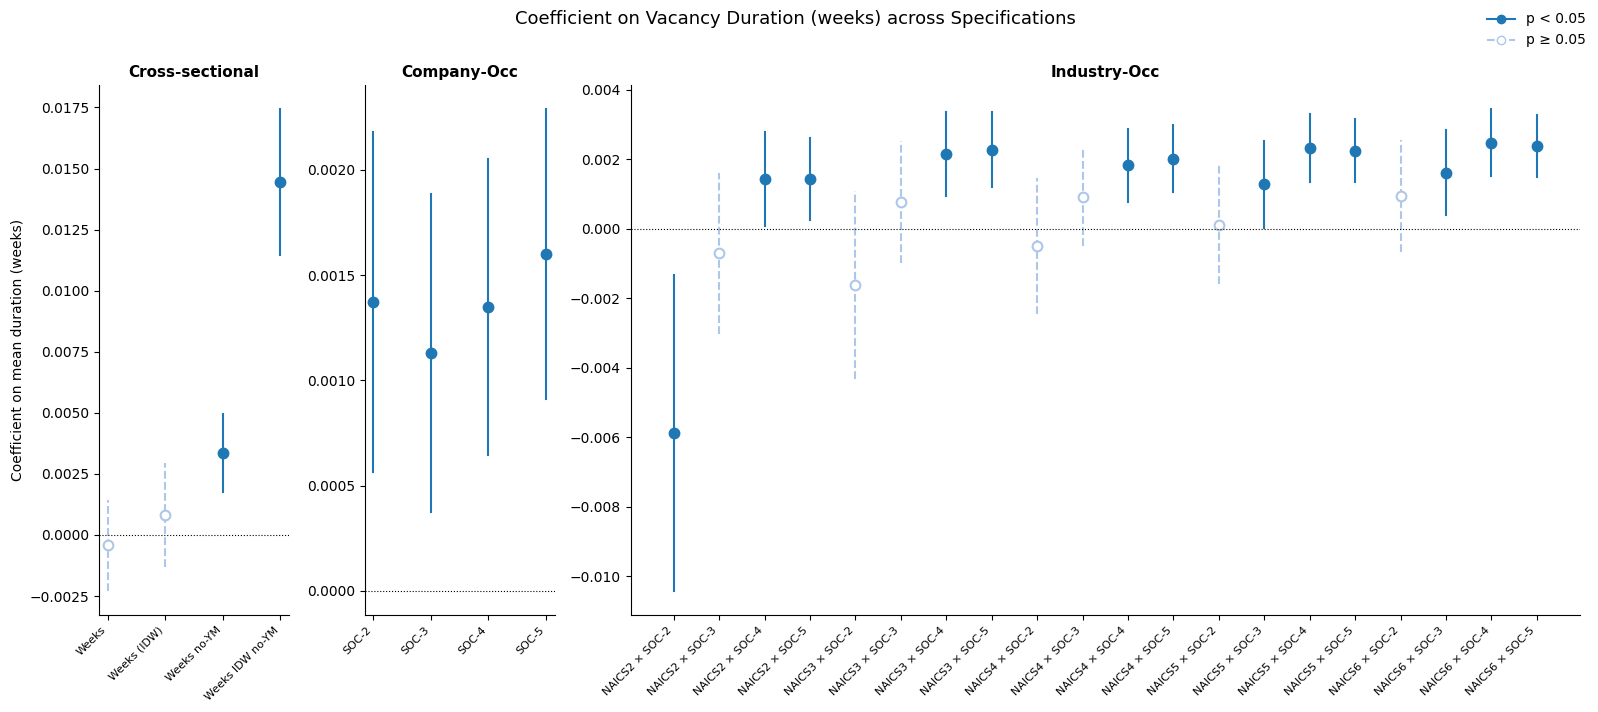

: 

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import pandas as pd
import numpy as np
import os

# ── 1. Load coefficients of interest ────────────────────────────────────────

rows = []

# Cross-sectional: duration_weeks coefficient only
cs = pd.read_csv(f'{cache_prefix}coefs_cross_section_tidy.csv')
cs = cs[cs["Coefficient"] == "duration_weeks"]
for _, r in cs.iterrows():
    rows.append({
        "group":  "Cross-sectional",
        "label":  r["model"],
        "coef":   r["Estimate"],
        "ci_lo":  r["Estimate"] - 1.96 * r["Std. Error"],
        "ci_hi":  r["Estimate"] + 1.96 * r["Std. Error"],
        "pval":   r["Pr(>|t|)"],
    })

# Company-occ: Mean (weeks) coefficient
for soc in ["soc_2", "soc_3", "soc_4", "soc_5"]:
    path = f'{cache_prefix}firm_occ_results_{soc}_tidy.csv'
    if not os.path.exists(path): continue
    df = pd.read_csv(path)
    df = df[(df["model"] == "Mean (weeks)") & (df["Coefficient"] == "mean_dur_weeks")]
    for _, r in df.iterrows():
        rows.append({
            "group":  "Company-Occ",
            "label":  soc.upper().replace("_", "-"),
            "coef":   r["Estimate"],
            "ci_lo":  r["Estimate"] - 1.96 * r["Std. Error"],
            "ci_hi":  r["Estimate"] + 1.96 * r["Std. Error"],
            "pval":   r["Pr(>|t|)"],
        })

# Industry-occ: Mean (weeks) coefficient
for naics in ["naics2", "naics3", "naics4", "naics5", "naics6"]:
    for soc in ["soc_2", "soc_3", "soc_4", "soc_5"]:
        path = f'{cache_prefix}ind_occ_{naics}_{soc}_tidy.csv'
        if not os.path.exists(path): continue
        df = pd.read_csv(path)
        df = df[(df["model"] == "Mean (weeks)") & (df["Coefficient"] == "mean_dur_weeks")]
        for _, r in df.iterrows():
            rows.append({
                "group":  "Industry-Occ",
                "label":  f"{naics.upper()} × {soc.upper().replace('_','-')}",
                "coef":   r["Estimate"],
                "ci_lo":  r["Estimate"] - 1.96 * r["Std. Error"],
                "ci_hi":  r["Estimate"] + 1.96 * r["Std. Error"],
                "pval":   r["Pr(>|t|)"],
            })

plot_df = pd.DataFrame(rows)
plot_df["sig"] = plot_df["pval"] < 0.05

# ── 2. Plot ──────────────────────────────────────────────────────────────────

groups     = ["Cross-sectional", "Company-Occ", "Industry-Occ"]
group_data = {g: plot_df[plot_df["group"] == g].reset_index(drop=True) for g in groups}
n_panels   = len(groups)

fig, axes = plt.subplots(1, n_panels, figsize=(16, 7),
                         gridspec_kw={"width_ratios": [len(group_data[g]) for g in groups]})

for ax, group in zip(axes, groups):
    data = group_data[group]
    x    = np.arange(len(data))

    for i, row in data.iterrows():
        color    = "#1f77b4" if row["sig"] else "#aec7e8"
        ls       = "-"       if row["sig"] else "--"
        marker   = "o"       if row["sig"] else "o"
        mfc      = color     if row["sig"] else "white"

        ax.plot([i, i], [row["ci_lo"], row["ci_hi"]],
                color=color, lw=1.5, ls=ls, zorder=1)
        ax.plot(i, row["coef"],
                marker=marker, color=color, mfc=mfc,
                ms=7, zorder=2, mew=1.5)

    ax.axhline(0, color="black", lw=0.8, ls=":")
    ax.set_xticks(x)
    ax.set_xticklabels(data["label"], rotation=45, ha="right", fontsize=8)
    ax.set_title(group, fontsize=11, fontweight="bold")
    ax.set_ylabel("Coefficient on mean duration (weeks)" if ax == axes[0] else "")
    ax.spines[["top", "right"]].set_visible(False)

# Legend
sig_line   = mlines.Line2D([], [], color="#1f77b4",  ls="-",  marker="o", label="p < 0.05")
insig_line = mlines.Line2D([], [], color="#aec7e8", ls="--", marker="o", mfc="white", label="p ≥ 0.05")
fig.legend(handles=[sig_line, insig_line], loc="upper right", frameon=False)

plt.suptitle("Coefficient on Vacancy Duration (weeks) across Specifications",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{cache_prefix}coefficient_plot.png', dpi=150, bbox_inches="tight")
plt.show()


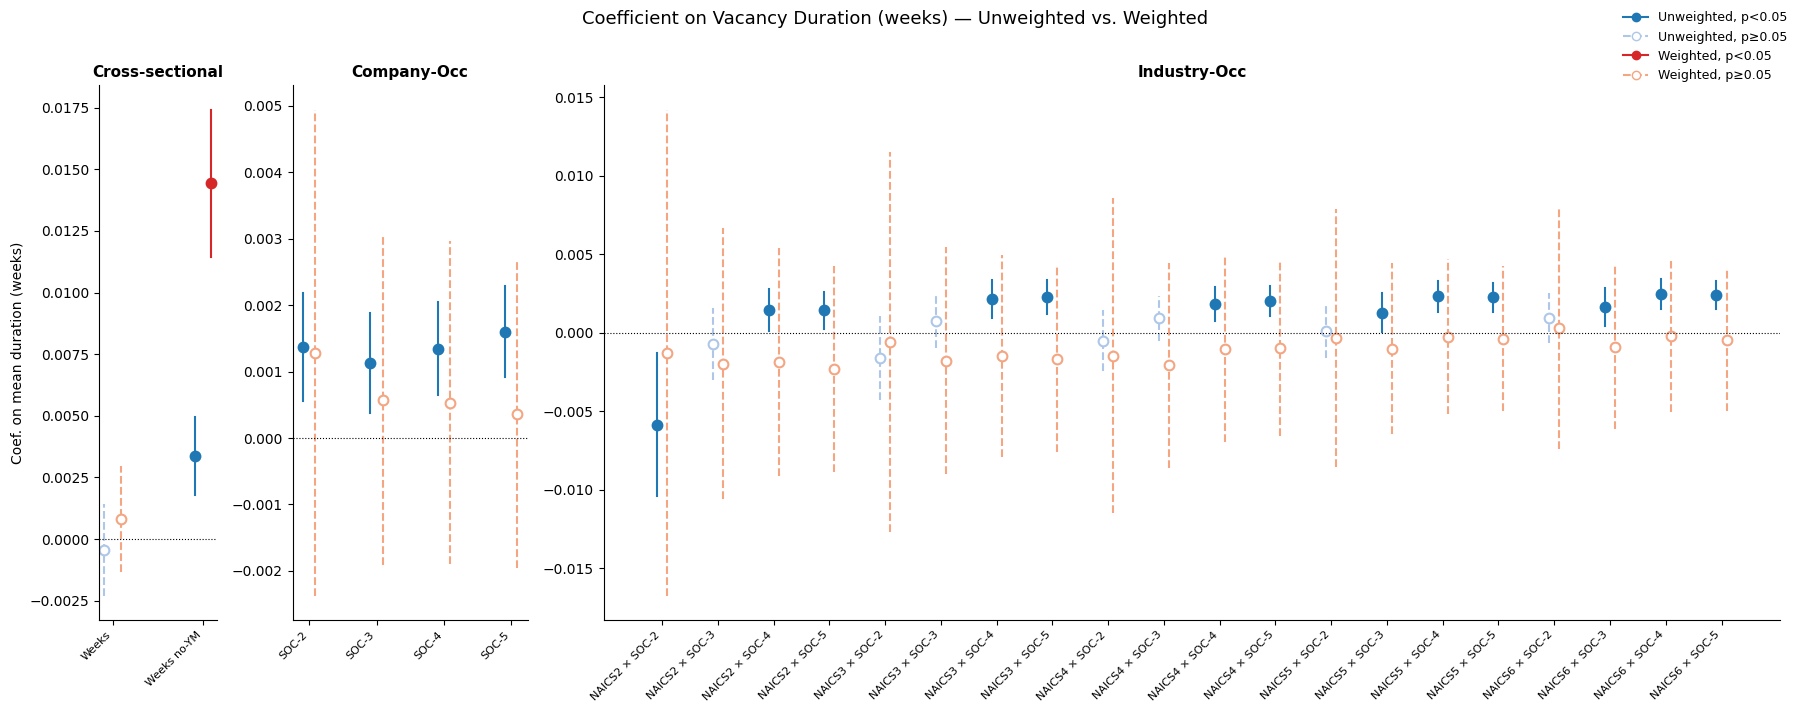

In [64]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import pandas as pd
import numpy as np
import os

OFFSET = 0.18   # horizontal jitter between unweighted and weighted

# ── 1. Load coefficients ─────────────────────────────────────────────────────

rows = []

# Cross-sectional — unweighted: "Weeks", weighted: "Weeks (IDW)"
cs = pd.read_csv(f'{cache_prefix}coefs_cross_section_tidy.csv')
cs = cs[cs["Coefficient"] == "duration_weeks"]
pairs = [("Weeks", "Weeks (IDW)"), ("Weeks no-YM", "Weeks IDW no-YM")]
for base_label, (unw_name, w_name) in enumerate(pairs):
    for weighted, name in [(False, unw_name), (True, w_name)]:
        r = cs[cs["model"] == name].iloc[0]
        rows.append({
            "group":    "Cross-sectional",
            "label":    unw_name,           # shared x-label
            "coef":     r["Estimate"],
            "ci_lo":    r["Estimate"] - 1.96 * r["Std. Error"],
            "ci_hi":    r["Estimate"] + 1.96 * r["Std. Error"],
            "pval":     r["Pr(>|t|)"],
            "weighted": weighted,
        })

# Company-occ — unweighted: "Mean (weeks)", weighted: "Weighted (weeks)"
for soc in ["soc_2", "soc_3", "soc_4", "soc_5"]:
    path = f'{cache_prefix}firm_occ_results_{soc}_tidy.csv'
    if not os.path.exists(path): continue
    df = pd.read_csv(path)
    df = df[df["Coefficient"] == "mean_dur_weeks"]
    for weighted, mname in [(False, "Mean (weeks)"), (True, "Weighted (weeks)")]:
        r = df[df["model"] == mname]
        if r.empty: continue
        r = r.iloc[0]
        rows.append({
            "group":    "Company-Occ",
            "label":    soc.upper().replace("_", "-"),
            "coef":     r["Estimate"],
            "ci_lo":    r["Estimate"] - 1.96 * r["Std. Error"],
            "ci_hi":    r["Estimate"] + 1.96 * r["Std. Error"],
            "pval":     r["Pr(>|t|)"],
            "weighted": weighted,
        })

# Industry-occ — unweighted: "Mean (weeks)", weighted: "Weighted (weeks)"
for naics in ["naics2", "naics3", "naics4", "naics5", "naics6"]:
    for soc in ["soc_2", "soc_3", "soc_4", "soc_5"]:
        path = f'{cache_prefix}ind_occ_{naics}_{soc}_tidy.csv'
        if not os.path.exists(path): continue
        df = pd.read_csv(path)
        df = df[df["Coefficient"] == "mean_dur_weeks"]
        for weighted, mname in [(False, "Mean (weeks)"), (True, "Weighted (weeks)")]:
            r = df[df["model"] == mname]
            if r.empty: continue
            r = r.iloc[0]
            rows.append({
                "group":    "Industry-Occ",
                "label":    f"{naics.upper()} × {soc.upper().replace('_','-')}",
                "coef":     r["Estimate"],
                "ci_lo":    r["Estimate"] - 1.96 * r["Std. Error"],
                "ci_hi":    r["Estimate"] + 1.96 * r["Std. Error"],
                "pval":     r["Pr(>|t|)"],
                "weighted": weighted,
            })

plot_df       = pd.DataFrame(rows)
plot_df["sig"] = plot_df["pval"] < 0.05

# ── 2. Plot ───────────────────────────────────────────────────────────────────

COLOR_UNW = {"sig": "#1f77b4", "insig": "#aec7e8"}   # blue
COLOR_W   = {"sig": "#d62728", "insig": "#f4a582"}    # red

groups     = ["Cross-sectional", "Company-Occ", "Industry-Occ"]
group_data = {g: plot_df[plot_df["group"] == g] for g in groups}

fig, axes = plt.subplots(
    1, len(groups), figsize=(18, 7),
    gridspec_kw={"width_ratios": [
        plot_df[plot_df["group"] == g]["label"].nunique() for g in groups
    ]}
)

for ax, group in zip(axes, groups):
    data   = group_data[group]
    labels = data["label"].unique()
    x_map  = {lbl: i for i, lbl in enumerate(labels)}

    for _, row in data.iterrows():
        xi     = x_map[row["label"]]
        offset = -OFFSET/2 if not row["weighted"] else OFFSET/2
        colors = COLOR_UNW if not row["weighted"] else COLOR_W
        color  = colors["sig"] if row["sig"] else colors["insig"]
        ls     = "-"  if row["sig"] else "--"
        mfc    = color if row["sig"] else "white"

        ax.plot([xi + offset, xi + offset], [row["ci_lo"], row["ci_hi"]],
                color=color, lw=1.5, ls=ls, zorder=1)
        ax.plot(xi + offset, row["coef"],
                marker="o", color=color, mfc=mfc,
                ms=7, zorder=2, mew=1.5)

    ax.axhline(0, color="black", lw=0.8, ls=":")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_title(group, fontsize=11, fontweight="bold")
    ax.set_ylabel("Coef. on mean duration (weeks)" if ax == axes[0] else "")
    ax.spines[["top", "right"]].set_visible(False)

# Legend
handles = [
    mlines.Line2D([], [], color=COLOR_UNW["sig"],   ls="-",  marker="o", label="Unweighted, p<0.05"),
    mlines.Line2D([], [], color=COLOR_UNW["insig"], ls="--", marker="o", mfc="white", label="Unweighted, p≥0.05"),
    mlines.Line2D([], [], color=COLOR_W["sig"],     ls="-",  marker="o", label="Weighted, p<0.05"),
    mlines.Line2D([], [], color=COLOR_W["insig"],   ls="--", marker="o", mfc="white", label="Weighted, p≥0.05"),
]
fig.legend(handles=handles, loc="upper right", frameon=False, fontsize=9)
plt.suptitle("Coefficient on Vacancy Duration (weeks) — Unweighted vs. Weighted",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{cache_prefix}coefficient_plot.png', dpi=150, bbox_inches="tight")
plt.show()
